# 05 · Machine learning

**Question:** under the grouped protocol from notebook 04, does any classical model, with any of the
planned imbalance treatments, predict the 8 classes better than the baselines?

**The menu was fixed before running** (project plan, section 7) and every result is shown, not just
the best:

| model | why it is on the list | tuned in the inner loop |
|---|---|---|
| logistic regression (L2) | simple, well-calibrated reference | C, class weights |
| k-nearest neighbours | do similar-sounding cries share labels? | k, distance weighting |
| SVM, RBF kernel | strong on small tabular data | C, class weights |
| random forest | non-linear, no scaling needed | depth, min leaf size, class weights |
| histogram gradient boosting | usually the strongest tabular model | learning rate, depth, sample weights |

**Imbalance treatments**, each tested rather than assumed to help:
- class weights: none, inverse frequency ("balanced"), or its square root, chosen in the inner loop;
- the **prior-corrected decision rule** argmax log p − τ·log prior, with τ ∈ {0, 0.25, 0.5, 0.75, 1}
  tuned in the inner loop. Each model is reported with plain argmax and with this rule;
- no oversampling or SMOTE. Copies of rare clips would bring back the duplicate problem from notebook 01.

**Nested CV** (`src/models.py`): for each of the 25 outer splits, a grouped 3-fold inner CV on the
outer *training* part scores every grid point by balanced accuracy on the pooled inner predictions.
The winner is refitted on the whole training part and predicts the outer test fold, which is never used for any choice.

Input: the 225 band-limited features from notebook 03 (the default). The full-band set is run once at the end as
a sensitivity check.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

# src.models runs the outer splits in parallel processes with one native (OpenMP/BLAS) thread per fit.
# Telling joblib that each fit gets 1 core also skips its physical-core query, which fails in some
# sandboxes and prints a traceback. It only sizes thread pools; results do not change.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, load_clean_index
from src.features import BAND, feature_table, group_of
from src.metrics import (balanced_accuracy, cluster_bootstrap, encode, interval, macro_f1,
                         paired_bootstrap, per_class_table, predictions_by_repeat, repeat_scores)
from src.models import MENU, TAUS, VARIANTS, nested_oof
from src.splits import load_folds, load_predictions, repeats, save_predictions

viz.set_style()
pd.set_option("display.width", 160)
idx = load_clean_index()
folds = load_folds(idx)
X = feature_table(BAND)
y, groups, t = idx["label"].to_numpy(), idx["source"].to_numpy(), encode(idx["label"])
RESULTS = REPO / "results"
print(f"{X.shape[1]} features, {len(idx)} clips, {len(repeats(folds))} repeats x 5 folds")
for name, (_, grid) in MENU.items():
    print(f"  {name}: {len(grid)} grid points x {len(TAUS)} values of tau")

225 features, 479 clips, 5 repeats x 5 folds
  logistic_regression: 12 grid points x 5 values of tau
  knn: 6 grid points x 5 values of tau
  svm_rbf: 9 grid points x 5 values of tau
  random_forest: 12 grid points x 5 values of tau
  hist_gradient_boosting: 12 grid points x 5 values of tau


## 1. Run the menu

About 12 minutes on an 11-core laptop (gradient boosting is 6 of them): 5 models × 25 outer splits × (grid × 3 inner fits + refits). Every
variant's out-of-fold predictions are saved to `results/predictions/ml_<model>_<variant>.csv`, and the choices made
in every split to `results/ml_tuning.csv`.

In [2]:
predictions, logs = {}, []
for name in MENU:
    start = time.time()
    pred, log = nested_oof(name, X, y, groups, folds)
    for variant in VARIANTS:
        predictions[(name, variant)] = pred[variant]
        save_predictions(f"ml_{name}_{variant}", pred[variant], idx)
    logs.append(log.assign(model=name))
    print(f"{name:24s} {time.time() - start:5.0f} s")
tuning = pd.concat(logs, ignore_index=True)
tuning.assign(params=tuning["params"].astype(str)).to_csv(RESULTS / "ml_tuning.csv", index=False)

logistic_regression         17 s


knn                         15 s


svm_rbf                     19 s


random_forest               51 s


hist_gradient_boosting     359 s


## 2. Scores

Metrics are means over the 5 repeats (± std across repeats). The 95% intervals come from the cluster
bootstrap over babies (1000 draws), and "vs majority" is the paired bootstrap difference in balanced
accuracy from the always-hungry baseline. The baselines from notebook 04 are included for reference.

In [3]:
majority = predictions_by_repeat(load_predictions("majority", idx), len(idx))


def evaluate(pred, n_boot=1000):
    per_rep = repeat_scores(pred)
    preds = predictions_by_repeat(pred, len(idx))
    row = {}
    for m in per_rep.columns:
        row[m] = per_rep[m].mean()
        row[f"{m}_std"] = per_rep[m].std(ddof=1)
    for m, fn in [("balanced_accuracy", balanced_accuracy), ("macro_f1", macro_f1)]:
        row[f"{m}_low"], row[f"{m}_high"] = interval(cluster_bootstrap(t, preds, groups, fn, n_boot, seed=0))
    d = paired_bootstrap(t, preds, majority, groups, n_boot=n_boot, seed=0)
    row["ba_vs_majority"], (row["ba_vs_majority_low"], row["ba_vs_majority_high"]) = d.mean(), interval(d)
    return row


rows = []
for name in ["majority", "prior_random"]:
    rows.append({"model": name, "variant": "baseline", "features": "-", **evaluate(load_predictions(name, idx))})
for (name, variant), pred in predictions.items():
    rows.append({"model": name, "variant": variant, "features": "band-limited, all groups", **evaluate(pred)})
scores = pd.DataFrame(rows)

show = scores.set_index(["model", "variant"])
pd.DataFrame({
    "balanced acc": show["balanced_accuracy"].map("{:.3f}".format) + " ± " + show["balanced_accuracy_std"].map("{:.3f}".format),
    "BA 95% CI": show["balanced_accuracy_low"].map("{:.3f}".format) + "-" + show["balanced_accuracy_high"].map("{:.3f}".format),
    "macro-F1": show["macro_f1"].map("{:.3f}".format) + " ± " + show["macro_f1_std"].map("{:.3f}".format),
    "BA vs majority (95% CI)": show["ba_vs_majority"].map("{:+.3f}".format) + " (" + show["ba_vs_majority_low"].map("{:+.3f}".format)
                               + ", " + show["ba_vs_majority_high"].map("{:+.3f}".format) + ")",
    "accuracy": show["accuracy"].round(3), "log-loss": show["log_loss"].round(3), "top-3": show["top3_accuracy"].round(3),
})

balanced acc    BA 95% CI       macro-F1  BA vs majority (95% CI)  accuracy  log-loss  top-3
model                  variant                                                                                                       
majority               baseline         0.125 ± 0.000  0.125-0.143  0.111 ± 0.000  +0.000 (+0.000, +0.000)     0.797     0.887  0.900
prior_random           baseline         0.132 ± 0.007  0.119-0.151  0.132 ± 0.007  +0.006 (-0.007, +0.022)     0.654     0.887  0.900
logistic_regression    argmax           0.125 ± 0.007  0.109-0.160  0.124 ± 0.006  +0.002 (-0.017, +0.026)     0.649     1.542  0.843
                       prior_corrected  0.103 ± 0.017  0.084-0.137  0.098 ± 0.008  -0.021 (-0.042, +0.006)     0.399     1.635  0.782
knn                    argmax           0.126 ± 0.003  0.122-0.145  0.115 ± 0.007  +0.001 (-0.003, +0.006)     0.785     4.883  0.866
                       prior_corrected  0.108 ± 0.012  0.092-0.139  0.109 ± 0.008  -0.017 (-0.034, +0.008)     0.517     4.517  0.865
svm_rbf                argmax           0.125 ± 0.000  0.124-0.143  0.111 ± 0.000  -0.000 (-0.001, +0.000)     0.796     0.891  0.894
                       prior_corrected  0.128 ± 0.006  0.115-0.153  0.126 ± 0.006  +0.003 (-0.010, +0.022)     0.682     0.907  0.886
random_forest          argmax           0.131 ± 0.005  0.123-0.152  0.125 ± 0.008  +0.006 (-0.002, +0.016)     0.784     1.213  0.871
                       prior_corrected  0.112 ± 0.023  0.084-0.145  0.094 ± 0.023  -0.014 (-0.042, +0.018)     0.262     1.267  0.875
hist_gradient_boosting argmax           0.126 ± 0.002  0.123-0.144  0.114 ± 0.004  +0.001 (-0.002, +0.005)     0.791     1.619  0.879
                       prior_corrected  0.116 ± 0.010  0.106-0.138  0.116 ± 0.009  -0.009 (-0.019, +0.005)     0.661     1.435  0.875

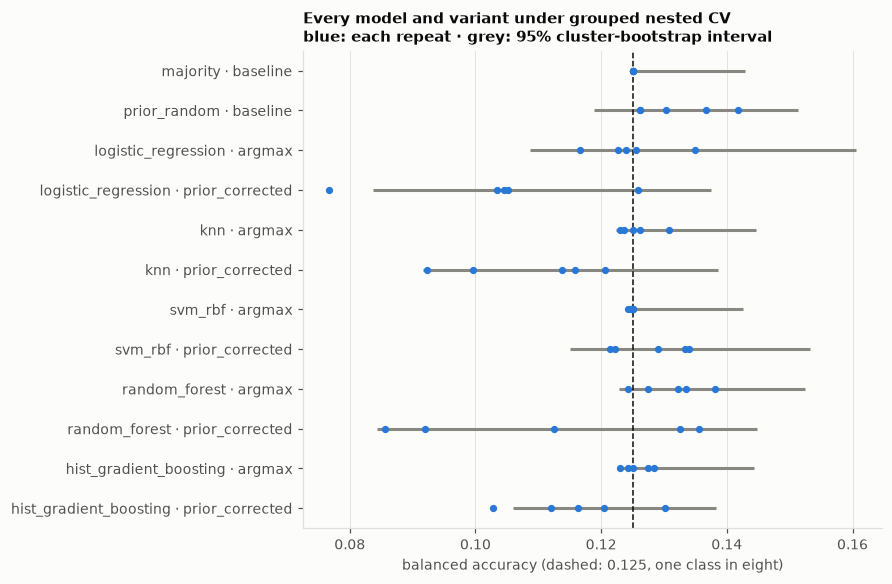

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.2), constrained_layout=True)
labels = [f"{m} · {v}" for m, v in zip(scores["model"], scores["variant"])]
for i, (_, r) in enumerate(scores.iterrows()):
    ax.plot([r["balanced_accuracy_low"], r["balanced_accuracy_high"]], [i, i], color=viz.GREY, lw=2, solid_capstyle="butt")
    pred = load_predictions(r["model"], idx) if r["variant"] == "baseline" else predictions[(r["model"], r["variant"])]
    ax.scatter(repeat_scores(pred)["balanced_accuracy"], np.full(5, i), color=viz.BLUE, s=14, zorder=3)
ax.axvline(0.125, color=viz.INK, lw=1, ls="--")
ax.set_yticks(range(len(labels)), labels)
ax.set_ylim(len(labels) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="balanced accuracy (dashed: 0.125, one class in eight)",
       title="Every model and variant under grouped nested CV\nblue: each repeat · grey: 95% cluster-bootstrap interval")
plt.show()

## 3. What the inner loop chose

The inner score is the balanced accuracy the inner CV *expected* for the chosen setting. Comparing it
with the outer score shows how optimistic the choice was.

In [5]:
inner = tuning.groupby(["model", "variant"])["inner_ba"].mean()
outer = scores.set_index(["model", "variant"])["balanced_accuracy"]
choices = pd.DataFrame({"inner BA of the chosen setting": inner, "outer BA": outer.reindex(inner.index)})
choices["most frequent setting (of 25 splits)"] = tuning.groupby(["model", "variant"])["params"].agg(
    lambda s: f"{s.astype(str).value_counts().index[0]} ({s.astype(str).value_counts().iloc[0]})")
choices["tau chosen (counts)"] = tuning.groupby(["model", "variant"])["tau"].agg(
    lambda s: ", ".join(f"{k:g}:{v}" for k, v in s.value_counts().sort_index().items()))
choices.round(3)

inner BA of the chosen setting  outer BA               most frequent setting (of 25 splits)  \
model                  variant                                                                                                        
hist_gradient_boosting argmax                                    0.128     0.126  {'lr': 0.1, 'max_depth': None, 'weight': None}...   
                       prior_corrected                           0.139     0.116  {'lr': 0.05, 'max_depth': 3, 'weight': 'balanc...   
knn                    argmax                                    0.127     0.126               {'k': 15, 'weights': 'uniform'} (14)   
                       prior_corrected                           0.140     0.108                {'k': 15, 'weights': 'uniform'} (7)   
logistic_regression    argmax                                    0.141     0.125                     {'C': 0.1, 'weight': None} (6)   
                       prior_corrected                           0.158     0.103             {'C': 0.001, 'weight': 'balanced'} (6)   
random_forest          argmax                                    0.133     0.131  {'max_depth': None, 'min_leaf': 5, 'weight': N...   
                       prior_corrected                           0.173     0.112  {'max_depth': None, 'min_leaf': 1, 'weight': N...   
svm_rbf                argmax                                    0.126     0.125                    {'C': 0.1, 'weight': None} (15)   
                       prior_corrected                           0.136     0.128              {'C': 10.0, 'weight': 'balanced'} (7)   

                                                     tau chosen (counts)  
model                  variant                                            
hist_gradient_boosting argmax                                       0:25  
                       prior_corrected  0:6, 0.25:1, 0.5:1, 0.75:7, 1:10  
knn                    argmax                                       0:25  
                       prior_corrected   0:7, 0.25:5, 0.5:5, 0.75:5, 1:3  
logistic_regression    argmax                                       0:25  
                       prior_corrected   0:9, 0.25:3, 0.5:5, 0.75:7, 1:1  
random_forest          argmax                                       0:25  
                       prior_corrected       0.25:3, 0.5:2, 0.75:2, 1:18  
svm_rbf                argmax                                       0:25  
                       prior_corrected   0:4, 0.25:3, 0.5:8, 0.75:6, 1:4

## 4. Is there any ranking signal?

Balanced accuracy only looks at the top guess. A model could still rank clips sensibly, giving the
true class a higher probability than other clips get, without that class ever winning the argmax.
One-vs-rest **AUROC** per class measures exactly this: 0.5 is chance, and below 0.5 means the model
systematically gives the class *less* probability on its own clips than on others. Averaged over
the 5 repeats, argmax variants (the probabilities are the same for both variants).

In [6]:
auc = {}
for name in MENU:
    pred = predictions[(name, "argmax")]
    auc[name] = pd.DataFrame({r: {c: roc_auc_score(g["y_true"] == c, g[f"p_{c}"]) for c in CLASSES}
                              for r, g in pred.groupby("repeat")}).mean(axis=1)
auc = pd.DataFrame(auc).T
babies = idx.groupby("label")["source"].nunique()
auc.columns = [f"{c} ({babies[c]})" for c in auc.columns]
print("one-vs-rest AUROC; number of babies in brackets")
auc.round(2)

one-vs-rest AUROC; number of babies in brackets


,belly_pain (7),burping (8),cold_hot (3),discomfort (14),hungry (205),lonely (8),scared (4),tired (17)
logistic_regression,0.46,0.59,0.41,0.44,0.50,0.60,0.36,0.45
knn,0.41,0.45,0.43,0.49,0.55,0.50,0.52,0.56
svm_rbf,0.40,0.54,0.23,0.59,0.54,0.46,0.50,0.54
random_forest,0.30,0.48,0.29,0.49,0.53,0.60,0.41,0.52
hist_gradient_boosting,0.45,0.49,0.47,0.50,0.53,0.56,0.59,0.53


## 5. The best variant in detail

The best variant is picked by mean balanced accuracy over the same CV that scores it, so its score is slightly
optimistic: the best of 10 chance-level variants will tend to sit above 0.125 by luck. Its per-class table
averages the 5 repeats. Classes with fewer than 5 babies are flagged as not reliably estimable.

In [7]:
ml = scores[scores["variant"] != "baseline"]
best = ml.loc[ml["balanced_accuracy"].idxmax()]
best_key = (best["model"], best["variant"])
print(f"best by mean balanced accuracy: {best_key[0]} ({best_key[1]}), "
      f"{best['balanced_accuracy']:.3f}, 95% CI {best['balanced_accuracy_low']:.3f}-{best['balanced_accuracy_high']:.3f}, "
      f"vs majority {best['ba_vs_majority']:+.3f} ({best['ba_vs_majority_low']:+.3f}, {best['ba_vs_majority_high']:+.3f})")

tables = [per_class_table(encode(g.sort_values("clip")["y_true"]), encode(g.sort_values("clip")["y_pred"]), groups)
          for _, g in predictions[best_key].groupby("repeat")]
# mean over repeats; precision is undefined (skipped) in a repeat where the class is never predicted
per_class = pd.concat([tbl[["predicted", "precision", "recall", "f1"]] for tbl in tables]).groupby(level=0, sort=False).mean()
per_class.insert(0, "babies", tables[0]["babies"])
per_class.insert(0, "clips", tables[0]["clips"])
per_class["reliable (5+ babies)"] = tables[0]["reliable"]
per_class.round(3)

best by mean balanced accuracy: random_forest (argmax), 0.131, 95% CI 0.123-0.152, vs majority +0.006 (-0.002, +0.016)


,clips,babies,predicted,precision,recall,f1,reliable (5+ babies)
belly_pain,16,7,2.4,0.000,0.000,0.000,True
burping,9,8,1.0,0.000,0.000,0.000,True
cold_hot,7,3,0.4,0.000,0.000,0.000,False
discomfort,21,14,1.0,0.000,0.000,0.000,True
hungry,382,205,465.8,0.802,0.977,0.881,True
lonely,11,8,1.2,0.000,0.000,0.000,True
scared,5,4,0.2,0.000,0.000,0.000,False
tired,28,17,7.0,0.334,0.071,0.116,True


## 6. Feature-group ablation and full-band check (best model)

The best model is re-run, with its full nested tuning, on growing subsets of the feature groups:
MFCC (B) → +spectral shape (C) → +pitch (D) → +rhythm and energy (E, F) → +log-mel bands (A, i.e. all).
Then it is run on the full-band features to see whether the band limit changed anything. These runs are
for understanding only. The headline result stays the pre-declared default above.

In [8]:
sets = {"B": "B", "B+C": "BC", "B+C+D": "BCD", "B+C+D+E+F": "BCDEF", "all (A-F)": "ABCDEF"}
best_name, best_variant = best_key
rows = []
for label, letters in sets.items():
    cols = [c for c in X.columns if group_of(c) in letters]
    if letters == "ABCDEF":
        pred = predictions[best_key]
    else:
        pred = nested_oof(best_name, X[cols], y, groups, folds)[0][best_variant]
    rows.append({"features": f"band-limited, {label}", "n features": len(cols), **evaluate(pred)})
X_full = feature_table(None)
pred_full = nested_oof(best_name, X_full, y, groups, folds)[0][best_variant]
rows.append({"features": "full band, all (A-F)", "n features": X_full.shape[1], **evaluate(pred_full)})
ablation = pd.DataFrame(rows)
ablation[["features", "n features", "balanced_accuracy", "balanced_accuracy_std", "balanced_accuracy_low",
          "balanced_accuracy_high", "macro_f1", "ba_vs_majority", "ba_vs_majority_low", "ba_vs_majority_high"]].round(3)

,features,n features,balanced_accuracy,balanced_accuracy_std,balanced_accuracy_low,balanced_accuracy_high,macro_f1,ba_vs_majority,ba_vs_majority_low,ba_vs_majority_high
0,"band-limited, B",120,0.136,0.005,0.123,0.162,0.131,0.011,-0.002,0.026
1,"band-limited, B+C",130,0.140,0.004,0.126,0.165,0.137,0.015,0.000,0.031
2,"band-limited, B+C+D",136,0.133,0.007,0.125,0.156,0.127,0.009,0.000,0.021
3,"band-limited, B+C+D+E+F",145,0.132,0.004,0.123,0.153,0.125,0.007,-0.002,0.018
4,"band-limited, all (A-F)",225,0.131,0.005,0.123,0.152,0.125,0.006,-0.002,0.016
5,"full band, all (A-F)",225,0.127,0.004,0.120,0.147,0.118,0.002,-0.005,0.013


In [9]:
out = pd.concat([scores, ablation.assign(model=best_name, variant=best_variant)
                 .loc[lambda d: d["features"] != "band-limited, all (A-F)"]], ignore_index=True)
out.to_csv(RESULTS / "ml_scores.csv", index=False, float_format="%.4f")
print(f"wrote results/ml_scores.csv ({len(out)} rows)")

wrote results/ml_scores.csv (17 rows)


## 7. Findings

- **No model beats the majority baseline.** Under grouped nested CV, the 10 variants score balanced accuracy 0.103 to
  0.131 against 0.125 for always-hungry. Every paired 95% interval against the majority baseline includes 0. The best,
  random forest (argmax), scores 0.131 (95% CI 0.123-0.152), +0.006 (-0.002, +0.016) vs majority, which is below the
  prior-random baseline's 0.132.
- **The argmax models collapse onto hungry.** kNN, SVM, random forest and gradient boosting reach 0.78-0.80 accuracy
  against majority's 0.797. SVM (argmax) gives exactly the majority scores (BA 0.125 ± 0.000, macro-F1 0.111). In the
  best model, hungry has recall 0.977 and the only other class with correct predictions is tired (recall 0.071,
  precision 0.334, about 7 tired predictions per repeat).
- **Prior correction hurts out of sample.** It lowers balanced accuracy for 4 of 5 models (logistic regression 0.125 →
  0.103, kNN 0.126 → 0.108, random forest 0.131 → 0.112, gradient boosting 0.126 → 0.116) and leaves SVM about the same
  (0.125 → 0.128). The inner loop still chose tau > 0 in most splits (16 to 25 of 25 per model), because the chosen
  settings score 0.136-0.173 there. This is selection optimism: with 5-28 clips per minority class, the best of up to
  12 grid points × 5 values of tau fits inner-fold noise.
- **No ranking signal.** The 40 one-vs-rest AUROCs range from 0.23 to 0.60, and hungry's are 0.50-0.55. Probability
  quality matches or trails the class prior: the best log-loss, 0.891 (SVM, argmax), is above majority's 0.887, and no
  model's top-3 accuracy exceeds the baseline's 0.900.
- **Feature subsets and the full band change little.** Re-running the random forest on growing feature groups gives
  0.131-0.140. B+C (MFCC means and spread plus pitch) is highest at 0.140, +0.015 (0.000, +0.031). This is a post-hoc
  pick among 6 subsets of a model that was itself picked as best of 10, and its interval touches 0, so it is not
  evidence of signal. Full-band features score 0.127 vs 0.131 band-limited, so the 44.1 kHz high band gives these
  models no visible shortcut. Notebook 06 checks this directly.
- **Conclusion for the project:** with 3 to 17 babies in each minority class, the hand-crafted descriptors do not
  separate the eight labels when the test babies are unseen. Notebook 06 looks at where the errors fall. Notebook 07
  tests whether a CNN on log-mel spectrograms does better.